# Question 3: Fitness-Driven Copy-Mutate Algorithm with Addition and Deletion

### Algorithm Improvements & Rubric Compliance:
1. **Fitness Assignment Based on Ingredient Popularity (7 marks):**
   - Each ingredient $i$ in the Nature Basket ($NB$) is assigned a fitness value proportional to its empirical frequency/popularity in the Assignment 1 dataset:
     $$\text{Fitness}(i) = \frac{\text{Frequency}(i)}{\sum_{j \in NB} \text{Frequency}(j)}$$
   - At every instance of replacement (modification), a candidate ingredient is picked and replaces the chosen recipe ingredient only if the candidate is **fitter** ($\text{Fitness}(i_{\text{candidate}}) > \text{Fitness}(i_{\text{recipe}})$) and not already present in the recipe.
2. **Recipe Size Distribution Plot with Mean and SD (2 marks):** Plots the recipe size distribution across 5 random instances with its mean ($\mu$) and standard deviation ($\sigma$).
3. **Normalized Frequency-Rank Distribution Plot (1 mark):** Plots the normalized frequency-rank distribution across the 5 random instances on a log-log scale.

Total Ingredients in Nature Basket with Fitness Assigned: 13801
Top 5 Fittest Ingredients in Nature Basket:
  salt: Fitness = 0.04244
  sugar: Fitness = 0.03738
  onion: Fitness = 0.02535
  butter: Fitness = 0.02415
  garlic: Fitness = 0.02309

Running 5 instances of Fitness-Driven Copy-Mutate Evolution...
Instance 1/5 complete: Mean Size = 9.03, SD = 1.65
Instance 2/5 complete: Mean Size = 9.05, SD = 1.65
Instance 3/5 complete: Mean Size = 9.09, SD = 1.60
Instance 4/5 complete: Mean Size = 8.97, SD = 1.54
Instance 5/5 complete: Mean Size = 9.06, SD = 1.63


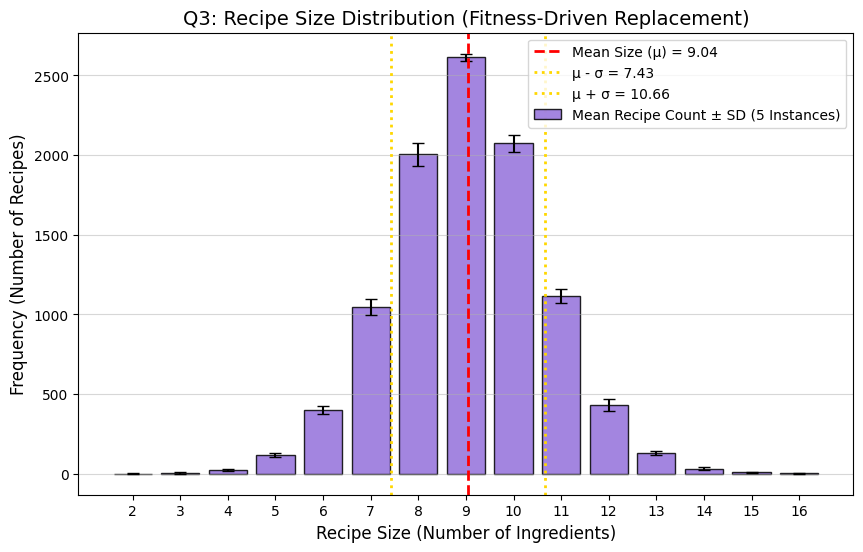

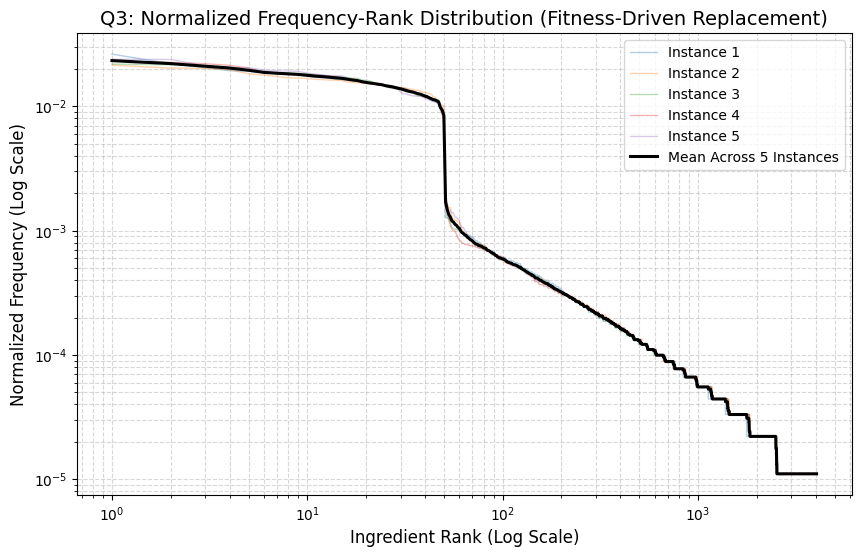

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import Counter

# ==========================================
# 1. Load Data & Assign Fitness to Nature Basket (7 marks)
# ==========================================
df_raw = pd.read_csv("1b_extracted_ingredients.csv")
df_raw['Ingredient Name'] = df_raw['Ingredient Name'].fillna("").astype(str).str.strip()
df_raw = df_raw[df_raw['Ingredient Name'] != ""]

empirical_recipe_sizes = df_raw.groupby('Recipe ID').size()
s = int(round(empirical_recipe_sizes.mean()))
total_target_recipes = int(empirical_recipe_sizes.shape[0])

# Compute empirical frequency/popularity of each ingredient in the Nature Basket
ing_freq_series = df_raw['Ingredient Name'].value_counts()
total_ing_occurrences = ing_freq_series.sum()

# Assign fitness values to each ingredient in Nature Basket according to popularity
fitness_dict = (ing_freq_series / total_ing_occurrences).to_dict()
nature_basket = list(fitness_dict.keys())
size_nb = len(nature_basket)

num_epochs = int(round(10))
n_r_t0 = int(round(200))
recipes_per_epoch = int(round((total_target_recipes - n_r_t0) / num_epochs))
initial_kb_size = int(round(50))
kb_step_per_epoch = int(round((size_nb - initial_kb_size) / num_epochs))

print(f"Total Ingredients in Nature Basket with Fitness Assigned: {size_nb}")
print("Top 5 Fittest Ingredients in Nature Basket:")
for ing, fit in list(fitness_dict.items())[:5]:
    print(f"  {ing}: Fitness = {fit:.5f}")

def initialize_primordial_cuisine(nb, n_r_0, recipe_size, kb_0_size):
    shuffled_nb = nb.copy()
    random.shuffle(shuffled_nb)
    kb = shuffled_nb[:kb_0_size]
    remaining_nb = shuffled_nb[kb_0_size:]

    cuisine_list = []
    cuisine_set = set()
    while len(cuisine_list) < n_r_0:
        recipe = sorted(random.sample(kb, recipe_size))
        recipe_key = frozenset(recipe)
        if recipe_key not in cuisine_set:
            cuisine_set.add(recipe_key)
            cuisine_list.append(recipe)
    return cuisine_list, cuisine_set, kb, remaining_nb

# ==========================================
# 2. Fitness-Driven Replacement, Addition & Deletion
# ==========================================
def modify_ingredient_fitness(recipe, kb, fitness_map):
    """
    Picks an ingredient from the recipe and replaces it with a FITTER ingredient from KB.
    Includes a popularity-weighted fallback if the recipe already holds the top fittest ingredients in KB.
    """
    new_rec = recipe.copy()
    rec_set = set(new_rec)

    max_attempts = 60
    for _ in range(max_attempts):
        idx = random.randrange(len(new_rec))
        rec_ing = new_rec[idx]
        kb_ing = random.choice(kb)

        # Replace if KB ingredient is not in recipe AND is fitter than the recipe ingredient
        if kb_ing != rec_ing and kb_ing not in rec_set:
            if fitness_map[kb_ing] > fitness_map[rec_ing]:
                new_rec[idx] = kb_ing
                return new_rec

    # Fallback if recipe already contains the highest-fitness ingredients in current KB:
    # Pick candidate from KB weighted by fitness
    available_kb = [ing for ing in kb if ing not in rec_set]
    if available_kb:
        weights = np.array([fitness_map[ing] for ing in available_kb])
        weights = weights / weights.sum()
        chosen_kb_ing = np.random.choice(available_kb, p=weights)
        idx = random.randrange(len(new_rec))
        new_rec[idx] = chosen_kb_ing

    return new_rec

def add_ingredient(recipe, kb, fitness_map):
    """Adds an ingredient from KB to the recipe."""
    new_rec = recipe.copy()
    rec_set = set(new_rec)
    if len(rec_set) >= len(kb):
        return modify_ingredient_fitness(new_rec, kb, fitness_map)
    while True:
        kb_ing = random.choice(kb)
        if kb_ing not in rec_set:
            new_rec.append(kb_ing)
            break
    return new_rec

def delete_ingredient(recipe, kb, fitness_map, min_size=2):
    """Deletes a random ingredient from the recipe while keeping size >= min_size."""
    new_rec = recipe.copy()
    if len(new_rec) <= min_size:
        return add_ingredient(new_rec, kb, fitness_map)
    idx = random.randrange(len(new_rec))
    new_rec.pop(idx)
    return new_rec

def mutate_q3(cuisine_list, kb, fitness_map):
    chosen_recipe = random.choice(cuisine_list).copy()
    operation = random.choice(['modify', 'add', 'delete'])

    if operation == 'modify':
        return modify_ingredient_fitness(chosen_recipe, kb, fitness_map)
    elif operation == 'add':
        return add_ingredient(chosen_recipe, kb, fitness_map)
    else:
        return delete_ingredient(chosen_recipe, kb, fitness_map, min_size=2)

def run_q3_simulation():
    cuisine_list, cuisine_set, kb, remaining_nb = initialize_primordial_cuisine(
        nature_basket, n_r_t0, s, initial_kb_size
    )

    for epoch in range(1, num_epochs + 1):
        if remaining_nb:
            add_count = min(kb_step_per_epoch, len(remaining_nb))
            kb.extend(remaining_nb[:add_count])
            remaining_nb = remaining_nb[add_count:]

        target_count = n_r_t0 + epoch * recipes_per_epoch
        while len(cuisine_list) < target_count:
            new_recipe = mutate_q3(cuisine_list, kb, fitness_dict)
            recipe_key = frozenset(new_recipe)
            if recipe_key not in cuisine_set:
                cuisine_set.add(recipe_key)
                cuisine_list.append(new_recipe)

    return cuisine_list

# ==========================================
# 3. Run 5 Instances of Cuisine Evolution
# ==========================================
num_instances = 5
q3_instance_sizes = []
q3_instance_norm_freqs = []

print(f"\nRunning {num_instances} instances of Fitness-Driven Copy-Mutate Evolution...")
for inst in range(num_instances):
    final_cuisine = run_q3_simulation()
    sizes = [len(r) for r in final_cuisine]
    q3_instance_sizes.append(sizes)

    all_ings = [ing for r in final_cuisine for ing in r]
    counts = np.array(sorted(Counter(all_ings).values(), reverse=True))
    q3_instance_norm_freqs.append(counts / counts.sum())
    print(f"Instance {inst+1}/{num_instances} complete: Mean Size = {np.mean(sizes):.2f}, SD = {np.std(sizes):.2f}")

# ==========================================
# 4. Plot Recipe Size Distribution with Mean & SD (2 marks)
# ==========================================
all_sizes_flat = np.concatenate(q3_instance_sizes)
overall_mean = np.mean(all_sizes_flat)
overall_std = np.std(all_sizes_flat)

min_s, max_s = int(min(all_sizes_flat)), int(max(all_sizes_flat))
size_bins = np.arange(min_s, max_s + 1)
size_matrix = np.zeros((num_instances, len(size_bins)))

for i, sizes in enumerate(q3_instance_sizes):
    c = Counter(sizes)
    for j, val in enumerate(size_bins):
        size_matrix[i, j] = c.get(val, 0)

mean_counts = size_matrix.mean(axis=0)
std_counts = size_matrix.std(axis=0)

plt.figure(figsize=(10, 6))
plt.bar(size_bins, mean_counts, yerr=std_counts, capsize=4, color='mediumpurple', edgecolor='black', alpha=0.85, label='Mean Recipe Count ± SD (5 Instances)')
plt.axvline(overall_mean, color='red', linestyle='--', linewidth=2, label=f'Mean Size (μ) = {overall_mean:.2f}')
plt.axvline(overall_mean - overall_std, color='gold', linestyle=':', linewidth=2, label=f'μ - σ = {overall_mean - overall_std:.2f}')
plt.axvline(overall_mean + overall_std, color='gold', linestyle=':', linewidth=2, label=f'μ + σ = {overall_mean + overall_std:.2f}')

plt.title('Q3: Recipe Size Distribution (Fitness-Driven Replacement)', fontsize=14)
plt.xlabel('Recipe Size (Number of Ingredients)', fontsize=12)
plt.ylabel('Frequency (Number of Recipes)', fontsize=12)
plt.xticks(np.arange(min_s, max_s + 1, max(1, (max_s - min_s) // 15)))
plt.legend(fontsize=10)
plt.grid(axis='y', alpha=0.5)
plt.savefig("Q3_Recipe_Size_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 5. Plot Normalized Frequency-Rank Distribution (1 mark)
# ==========================================
plt.figure(figsize=(10, 6))
min_ranks = min(len(nf) for nf in q3_instance_norm_freqs)
freq_matrix = np.array([nf[:min_ranks] for nf in q3_instance_norm_freqs])
ranks = np.arange(1, min_ranks + 1)

for i in range(num_instances):
    plt.loglog(ranks, freq_matrix[i], alpha=0.35, linewidth=1, label=f'Instance {i+1}')

plt.loglog(ranks, freq_matrix.mean(axis=0), color='black', linewidth=2.2, label='Mean Across 5 Instances')
plt.title('Q3: Normalized Frequency-Rank Distribution (Fitness-Driven Replacement)', fontsize=14)
plt.xlabel('Ingredient Rank (Log Scale)', fontsize=12)
plt.ylabel('Normalized Frequency (Log Scale)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig("Q3_Normalized_Frequency_Rank_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()